## License

Copyright (c) 2020–2027 Patrick Hall (jphall@gwu.edu)

This software is licensed under the MIT License. See [SOFTWARE_LICENSE.txt](SOFTWARE_LICENSE.txt) for details.

**DISCLAIMER:** This notebook is not legal compliance advice.

***

# Lecture 6: Neural Additive Models and Tabular Foundation Models

This notebook compares two main-effects neural approaches for predicting credit card default. The first uses frozen [NVIDIA Kumo Tabular](https://docs.nvidia.com/sdgm/structured-data-models/models/kumo-tabular) predictions from one feature at a time, then combines those feature scores with a logistic regression model. The second trains the [NAMpy neural additive model](https://github.com/AnFreTh/NAMpy) with a separate feature network for each input.

Both models are additive on the log-odds scale. The Kumo weights are pretrained and fixed; the logistic combiner is fitted to this task. NAMpy trains its feature networks on this task. The comparison uses a shared train, validation, and test split, but the training procedures and access to pretraining are different. This is a teaching comparison, not a controlled comparison of equal training data or equal compute.

The models use only main effects. No pairwise interactions are selected or fitted. We will compare held-out classification quality, then inspect centered component functions and local contributions. The components describe predictive associations, not causal effects. Kumo uses CUDA or Apple MPS when PyTorch reports it available, with a CPU fallback. NAMpy uses the devices exposed by TensorFlow. NVIDIA releases Kumo's weights under the [Open Model Weights license](https://huggingface.co/nvidia/Kumo-Tabular); the NAMpy source is [MIT licensed](https://github.com/AnFreTh/NAMpy).

#### Global settings

In [1]:
# Fixed settings make the data partitions, context rows, and training repeatable.
SEED = 12345
CONTEXT_SIZE = 2048  # Lowest median roughness across sparse numeric bins in the sweep.
REFERENCE_SIZE = 512
KUMO_QUERY_BATCH_SIZE = 512
KUMO_NUM_ESTIMATORS = 8  # Average randomized estimator views to reduce prediction variability.
KUMO_PROBABILITY_CLIP = 1e-6
NAM_MAX_EPOCHS = 50
NAM_EARLY_STOPPING_PATIENCE = 6
NAM_BATCH_SIZE = 1024


#### Python imports and initializations

In [2]:
# Configure caches and reduce routine backend logging before importing plotting and neural libraries.
import os
import platform
import tempfile
import time
import warnings

os.environ.setdefault("MPLCONFIGDIR", os.path.join(tempfile.gettempdir(), "gwu-rml-matplotlib"))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")  # Hide routine TensorFlow CPU feature notices.
os.environ.setdefault("OMP_NUM_THREADS", "4")

warnings.filterwarnings(
    "ignore",
    message=".*oneDNN.*",
    category=UserWarning,
)  # TensorFlow's CPU-kernel notice does not affect the model definition.
warnings.filterwarnings(
    "ignore",
    message="IProgress not found.*",
    category=Warning,
)  # NAMpy's optional notebook progress widget is not needed for model execution.

from IPython.display import display
from contextlib import redirect_stderr, redirect_stdout
from io import StringIO
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibrationDisplay
import torch
import tensorflow as tf
import sdm

from nampy.models.NAM import NAM

tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("NumPy:", np.__version__)
print("scikit-learn:", __import__("sklearn").__version__)
print("PyTorch:", torch.__version__)
print("TensorFlow:", tf.__version__)
print("Kumo Structured Data Models:", getattr(sdm, "__version__", "version is not exposed"))
cuda_available = torch.cuda.is_available()
mps_available = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
kumo_device = "cuda" if cuda_available else "mps" if mps_available else "cpu"
print("Host:", platform.platform(), "machine:", platform.machine())
print("PyTorch CUDA available:", cuda_available)
print("PyTorch MPS available:", mps_available)
print("Kumo inference device:", kumo_device)
print("NAMpy TensorFlow devices:", tf.config.list_physical_devices())


NumPy: 1.26.4
scikit-learn: 1.9.1
PyTorch: 2.15.0
TensorFlow: 2.15.1
Kumo Structured Data Models: 0.2.1
Host: macOS-26.7.3-arm64-arm-64bit machine: arm64
PyTorch CUDA available: False
PyTorch MPS available: True
Kumo inference device: mps
NAMpy TensorFlow devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


#### Start global timer

In [3]:
big_tic = time.time()

## 1. Load and Check the Credit Default Data

The spreadsheet includes a descriptive row before the column names. As in the Lecture 1 EBM example, we skip that row and rename the target column. The data contain 30,000 observations, an identifier, 23 potential predictors, and a binary default outcome.

#### Import and inspect the spreadsheet

In [4]:
data = pd.read_excel("default_of_credit_card_clients.xls", skiprows=1)
data = data.rename(columns={"default payment next month": "DEFAULT_NEXT_MONTH"})

print("Data shape:", data.shape)
print("Columns:", data.columns.tolist())
print("Target values:", data["DEFAULT_NEXT_MONTH"].value_counts(dropna=False).sort_index().to_dict())
print("Missing values:", int(data.isna().sum().sum()))
display(data.head())


Data shape: (30000, 25)
Columns: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT_NEXT_MONTH']
Target values: {0: 23364, 1: 6636}
Missing values: 0


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT_NEXT_MONTH
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


#### Assign the target and feature roles

In [5]:
# assign target and inputs for models
y_name = 'DEFAULT_NEXT_MONTH'
x_names = [name for name in data.columns if name not in [y_name, 'ID', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']]
print('y_name =', y_name)
print('x_names =', x_names)

# These retained integer codes represent categories or repayment-status levels,
# rather than measurements with equal numerical spacing. Both libraries keep each
# original feature together: Kumo receives one categorical column, and NAMpy's feature
# network receives its one-hot encoding.
categorical_features = [
    "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6",
]
continuous_features = [name for name in x_names if name not in categorical_features]

assert len(x_names) == 19
assert not set(['ID', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', y_name]) & set(x_names)
assert data[y_name].dropna().isin([0, 1]).all()
assert data["ID"].is_unique
assert not data[x_names + [y_name]].isna().any().any()

print("Target coding: 1 = default; 0 = no default")
print("Model inputs:", len(x_names), "; categorical codes:", categorical_features)
print("Continuous-valued predictors:", len(continuous_features))
display(data[categorical_features].nunique().rename("number of observed codes").to_frame())


y_name = DEFAULT_NEXT_MONTH
x_names = ['LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
Target coding: 1 = default; 0 = no default
Model inputs: 19 ; categorical codes: ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
Continuous-valued predictors: 13


,number of observed codes
PAY_0,11
PAY_2,11
PAY_3,11
PAY_4,11
PAY_5,10
PAY_6,10


## 2. Create Reproducible Training, Validation, and Test Partitions

The first 60% is the labeled context/training partition. Kumo uses a fixed stratified subset of 2,048 rows from that partition as its in-context examples; the remaining training rows are not used to fit its frozen component models. NAMpy trains on the full 60% training partition. The 20% validation partition supports combiner regularization selection and NAM early stopping. The 20% test partition stays out of those choices.

#### Make stratified splits and choose fixed context/reference rows

In [6]:
all_rows = np.arange(len(data))
train_rows, remainder_rows = train_test_split(
    all_rows,
    test_size=0.40,
    random_state=SEED,
    stratify=data[y_name],
)
validation_rows, test_rows = train_test_split(
    remainder_rows,
    test_size=0.50,
    random_state=SEED,
    stratify=data.iloc[remainder_rows][y_name],
)

context_rows, noncontext_train_rows = train_test_split(
    train_rows,
    train_size=CONTEXT_SIZE,
    random_state=SEED + 1,
    stratify=data.iloc[train_rows][y_name],
)
reference_rows, _ = train_test_split(
    noncontext_train_rows,
    train_size=REFERENCE_SIZE,
    random_state=SEED + 2,
    stratify=data.iloc[noncontext_train_rows][y_name],
)

assert set(train_rows).isdisjoint(validation_rows)
assert set(train_rows).isdisjoint(test_rows)
assert set(validation_rows).isdisjoint(test_rows)
assert set(context_rows).isdisjoint(reference_rows)
assert set(context_rows).issubset(train_rows)
assert set(reference_rows).issubset(train_rows)

train_data = data.iloc[train_rows].reset_index(drop=True)
validation_data = data.iloc[validation_rows].reset_index(drop=True)
test_data = data.iloc[test_rows].reset_index(drop=True)
context_data = data.iloc[context_rows].reset_index(drop=True)
reference_data = data.iloc[reference_rows].reset_index(drop=True)

split_summary = pd.DataFrame(
    {"rows": [len(train_data), len(validation_data), len(test_data)]},
    index=["Training/context source", "Validation", "Test"],
)
display(split_summary)
print("Kumo labeled context rows:", len(context_data))
print("Training reference rows outside the Kumo context:", len(reference_data))


,rows
Training/context source,18000
Validation,6000
Test,6000


Kumo labeled context rows: 2048
Training reference rows outside the Kumo context: 512


Those 512 rows provide feature values for centering the plotted effects around a training-data baselines. All 19 feature effects in both models are centered using the same 512-row training reference sample. The removed means are added to each model’s effective intercept, so the predicted logits and probabilities stay unchanged. The notebook checks that the centered contributions reconstruct predictions on validation and test rows.

#### Verify the no-leakage boundaries

In [7]:
# Neither ID nor target is passed as a predictor. Kumo's feature inputs are built
# one column at a time; NAMpy's formula names the 19 model inputs explicitly.
assert "ID" not in x_names
assert y_name not in x_names
assert not (set(context_rows) & set(validation_rows))
assert not (set(context_rows) & set(test_rows))
assert not (set(reference_rows) & set(validation_rows))
assert not (set(reference_rows) & set(test_rows))

training_prevalence = train_data[y_name].mean()
print("Training prevalence for the constant-probability baseline:", round(training_prevalence, 4))
print("All leakage-boundary checks passed.")


Training prevalence for the constant-probability baseline: 0.2212
All leakage-boundary checks passed.


## 3. Frozen Kumo Single-Feature Models

For each feature, Kumo receives that feature alone and the same 2,048 labeled context rows. We average eight randomized estimator views per component, reuse the fitted context cache, and request predictions in batches. Each probability is clipped to [10⁻⁶, 1 − 10⁻⁶] before conversion to log-odds. This fixed clipping rule prevents infinite values; it applies equally to reference, validation, test, and plotted query rows.

The set of Kumo components is a derived general additive model (GAM), not a standard NAM. Its component functions come from separate pretrained in-context predictions, and only the L2-penalized logistic combiner is learned from this task.

**Context-size selection.** A validation sweep compared nested 1,024-, 2,048-, and 4,096-row contexts. The 2,048-row setting had the lowest median normalized second-difference roughness in low-support continuous-feature bins (0.028, versus 0.099 at 1,024 and 0.038 at 4,096); its nested-CV validation log loss was 0.4346. We retain 2,048 rows for this balance of sparse-region smoothness and validation performance; individual curves can still vary.

#### Define Kumo table conversion and batched inference

In [ ]:
KUMO_DEVICE = kumo_device  # Use an available accelerator, with CPU fallback.
kumo_model = sdm.models.KumoTabular(
    task="classification",
    size="small",
    device=KUMO_DEVICE,
)

def make_kumo_table(frame, feature_name, include_target=False):
    '''Convert one original feature to Kumo's typed single-table format.'''
    columns = [feature_name] + ([y_name] if include_target else [])
    one_feature = frame[columns].copy()
    overrides = {
        feature_name: "categorical" if feature_name in categorical_features else "numerical"
    }
    if include_target:
        overrides[y_name] = "categorical"
    stypes = sdm.infer_stypes(one_feature, overrides=overrides)
    return sdm.TableTensor.from_pandas(df=one_feature, stypes=stypes, device=KUMO_DEVICE)

def positive_class_probability(probability_table):
    '''Select class 1 by its label; output column order is not assumed.'''
    probability_frame = probability_table.to_pandas()
    positive_column = next(column for column in probability_frame.columns if str(column) == "1")
    return probability_frame[positive_column].to_numpy(dtype=float)

def score_kumo_queries(feature_name, query_frame):
    '''Score a feature in batches using the context cached by the preceding fit.'''
    batches = []
    for start in range(0, len(query_frame), KUMO_QUERY_BATCH_SIZE):
        query_batch = query_frame.iloc[start:start + KUMO_QUERY_BATCH_SIZE]
        query_table = make_kumo_table(query_batch, feature_name, include_target=False)
        batches.append(positive_class_probability(kumo_model.predict(query_table)))
    return np.concatenate(batches)

print("Kumo model:", type(kumo_model).__name__, "on", KUMO_DEVICE)


Kumo model: KumoTabular on mps


#### Generate feature-wise Kumo predictions

In [9]:
query_partitions = {
    "reference": reference_data,
    "validation": validation_data,
}
kumo_probability_features = {
    name: pd.DataFrame(index=np.arange(len(frame)))
    for name, frame in query_partitions.items()
}

for feature_number, feature_name in enumerate(x_names):
    context_table = make_kumo_table(context_data, feature_name, include_target=True)
    # Kumo's fit operation stores the labeled context for subsequent predict calls.
    # A fresh generator seed for each feature fixes its randomized estimator views.
    kumo_model.fit(
        x=context_table.drop_columns(y_name),
        y=context_table[y_name],
        num_estimators=KUMO_NUM_ESTIMATORS,
        generator=torch.Generator(device=KUMO_DEVICE).manual_seed(SEED + feature_number),
    )

    for partition_name, partition_frame in query_partitions.items():
        kumo_probability_features[partition_name][feature_name] = score_kumo_queries(
            feature_name,
            partition_frame,
        )

    print(f"Finished Kumo component {feature_number + 1:02d}/{len(x_names)}: {feature_name}")

def probability_features_to_log_odds(probability_frame):
    '''Apply the fixed clip before taking each feature probability's logit.'''
    clipped = np.clip(
        probability_frame.to_numpy(dtype=float),
        KUMO_PROBABILITY_CLIP,
        1.0 - KUMO_PROBABILITY_CLIP,
    )
    return pd.DataFrame(logit(clipped), columns=x_names)

kumo_reference = probability_features_to_log_odds(kumo_probability_features["reference"])
kumo_validation = probability_features_to_log_odds(kumo_probability_features["validation"])
print("Kumo-derived feature matrix shapes:", {
    "reference": kumo_reference.shape,
    "validation": kumo_validation.shape,
})


Finished Kumo component 01/19: LIMIT_BAL


Finished Kumo component 02/19: PAY_0


Finished Kumo component 03/19: PAY_2


Finished Kumo component 04/19: PAY_3


Finished Kumo component 05/19: PAY_4


Finished Kumo component 06/19: PAY_5


... (9 outputs left out)

Finished Kumo component 16/19: PAY_AMT3


Finished Kumo component 17/19: PAY_AMT4


Finished Kumo component 18/19: PAY_AMT5


Finished Kumo component 19/19: PAY_AMT6
Kumo-derived feature matrix shapes: {'reference': (512, 19), 'validation': (6000, 19)}


## 4. Fit the Logistic Combiner on Validation Data

The Kumo component predictions are fixed. A standardized L2-penalized logistic regression combines their log-odds. Standardization is inside the cross-validation pipeline, so each fold learns scaling from its own fitting rows. The regularization strength is selected with three-fold stratified cross-validation on validation rows only.

#### Select logistic regularization by validation cross-validation

In [10]:
combiner_pipeline = Pipeline(
    steps=[
        ("scale", StandardScaler()),
        ("logistic", LogisticRegression(
            solver="lbfgs",
            max_iter=2000,
            random_state=SEED,
            l1_ratio=0.0,
        )),
    ]
)
combiner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
combiner_search = GridSearchCV(
    estimator=combiner_pipeline,
    param_grid={"logistic__C": [0.01, 0.1, 1.0, 10.0]},
    scoring="neg_log_loss",
    cv=combiner_cv,
    n_jobs=1,
    refit=True,
)
combiner_search.fit(kumo_validation, validation_data[y_name])
kumo_combiner = combiner_search.best_estimator_

print("Selected validation-CV regularization:", combiner_search.best_params_)
print("Mean validation CV log loss:", round(-combiner_search.best_score_, 4))


Selected validation-CV regularization: {'logistic__C': 0.01}
Mean validation CV log loss: 0.4341


#### Center the Kumo component functions

In [11]:
# The declared reference distribution is a deterministic 512-row sample from the
# 60% training partition, excluded from Kumo's labeled context. Centering changes
# only the intercept; the combiner's predictions are unchanged.
scaler = kumo_combiner.named_steps["scale"]
logistic = kumo_combiner.named_steps["logistic"]
combiner_weights = logistic.coef_.ravel()
kumo_reference_means = kumo_reference.mean(axis=0).to_numpy()
kumo_centered_intercept = float(
    logistic.intercept_[0]
    + np.sum(combiner_weights * (kumo_reference_means - scaler.mean_) / scaler.scale_)
)

def kumo_centered_contributions(raw_feature_logits):
    '''Return centered additive logit contributions in original feature order.'''
    values = np.asarray(raw_feature_logits, dtype=float)
    return (values - kumo_reference_means) * (combiner_weights / scaler.scale_)

kumo_validation_logits = kumo_combiner.decision_function(kumo_validation)
kumo_validation_contributions = kumo_centered_contributions(kumo_validation)

assert np.allclose(
    kumo_centered_intercept + kumo_validation_contributions.sum(axis=1),
    kumo_validation_logits,
    atol=1e-8,
)
print("Kumo validation additive reconstruction passed.")


Kumo validation additive reconstruction passed.


## 5. Train a NAM with NAMpy

NAMpy's `NAM` builds one feature network per formula term. The retained financial measurements are cast to floating point; coded repayment-status values are passed as strings and one-hot encoded within each original-feature network. The 19 resulting terms are jointly optimized with binary cross-entropy on logits. NAMpy learns the category vocabulary from training rows; uncommon unseen levels map to the out-of-vocabulary category.

The formula interface at the pinned NAMpy revision requires an explicit `-1` or `+1` intercept token, but its `+1` branch is parsed as though it were a feature term. We use the supported no-intercept formula and center each learned term on the declared training reference sample; the removed term means are transferred to an effective intercept. This gives the same predictions and an interpretable baseline without changing NAMpy's training code.

We compare two learning rates using validation log loss. Each fit uses early stopping on validation loss with a fixed patience and maximum epoch count. The test rows are not used in fitting, early stopping, or selection.

#### Prepare NAMpy data and an additive formula

In [12]:
# NAMpy's preprocessing recognizes integer columns as categorical; cast continuous
# measurements to float and use strings for coded levels. StringLookup learns category
# vocabulary from training rows and handles rare unseen levels in validation/test.
def make_nam_frame(frame):
    result = frame[x_names + [y_name]].copy()
    result[continuous_features] = result[continuous_features].astype("float32")
    result[y_name] = result[y_name].astype("int64")
    for category_name in categorical_features:
        # StringLookup learns a fixed vocabulary from training and keeps the encoded
        # feature width fixed when a validation or test split lacks a rare code.
        result[category_name] = result[category_name].astype(str)
    return result

nam_train_data = make_nam_frame(train_data)
nam_validation_data = make_nam_frame(validation_data)
nam_reference_data = make_nam_frame(reference_data)

nam_terms = " + ".join(
    f"MLP({feature_name}; hidden_dims=[32, 16]; encoding="
    f"{'one_hot' if feature_name in categorical_features else 'normalized'})"
    for feature_name in x_names
)
nam_formula = f"{y_name} ~ -1 + {nam_terms}"
print("Number of NAM main-effect networks:", len(x_names))
print("First terms:", nam_formula[:240] + " ...")


Number of NAM main-effect networks: 19
First terms: DEFAULT_NEXT_MONTH ~ -1 + MLP(LIMIT_BAL; hidden_dims=[32, 16]; encoding=normalized) + MLP(PAY_0; hidden_dims=[32, 16]; encoding=one_hot) + MLP(PAY_2; hidden_dims=[32, 16]; encoding=one_hot) + MLP(PAY_3; hidden_dims=[32, 16]; encoding=one_ho ...


#### Fit and select NAM learning rate on validation rows

In [13]:
# The legacy Adam optimizer avoids a TensorFlow warning about slower optimizer
# implementations on Apple Silicon. Four CPU threads keep training practical on laptops.
nam_trials = []

def fit_one_nam(learning_rate):
    '''Fit one fixed setting while hiding NAMpy's per-column progress chatter.'''
    with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = NAM(
            formula=nam_formula,
            data=nam_train_data,
            val_data=nam_validation_data,
            classification=True,
            output_activation="linear",
            feature_dropout=0.05,
            batch_size=NAM_BATCH_SIZE,
            binning_task="classification",
        )
        model.compile(
            optimizer=tf.keras.optimizers.legacy.Adam(learning_rate=learning_rate),
            loss={"output": tf.keras.losses.BinaryCrossentropy(from_logits=True)},
        )
        early_stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=NAM_EARLY_STOPPING_PATIENCE,
            restore_best_weights=True,
        )
        history = model.fit(
            model.training_dataset,
            epochs=NAM_MAX_EPOCHS,
            verbose=0,
            validation_data=model.validation_dataset,
            callbacks=[early_stopping],
        )
    return model, history

for learning_rate in [0.001, 0.003]:
    fit_tic = time.time()
    nam_model, history = fit_one_nam(learning_rate)
    elapsed = time.time() - fit_tic
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    best_validation_loss = float(np.min(history.history["val_loss"]))
    nam_trials.append(
        {
            "learning_rate": learning_rate,
            "model": nam_model,
            "history": history,
            "best_epoch": best_epoch,
            "best_validation_log_loss": best_validation_loss,
            "fit_seconds": elapsed,
        }
    )
    print(
        f"learning_rate={learning_rate}: best epoch={best_epoch}, "
        f"validation log loss={best_validation_loss:.4f}, runtime={elapsed:.1f}s"
    )

best_nam_trial = min(nam_trials, key=lambda result: result["best_validation_log_loss"])
nam_model = best_nam_trial["model"]
nam_learning_rate = best_nam_trial["learning_rate"]
print("Selected learning rate:", nam_learning_rate)


learning_rate=0.001: best epoch=17, validation log loss=0.4363, runtime=6.9s


learning_rate=0.003: best epoch=17, validation log loss=0.4338, runtime=6.9s
Selected learning rate: 0.003


#### Extract NAMpy logits and direct feature-network outputs

In [14]:
def nam_predict_outputs(model, frame, batch_size=NAM_BATCH_SIZE):
    '''Apply NAMpy's fitted preprocessing, then return its output and feature terms.'''
    prediction_frame = frame.copy()
    prediction_frame[y_name] = 0  # The model formula excludes target from its inputs.
    with redirect_stdout(StringIO()), redirect_stderr(StringIO()):
        dataset = model._get_dataset(prediction_frame, batch_size=batch_size, shuffle=False)
        return model.predict(dataset, verbose=0)

nam_reference_outputs = nam_predict_outputs(nam_model, nam_reference_data)
nam_validation_outputs = nam_predict_outputs(nam_model, nam_validation_data)

nam_component_names = [
    f"Shapefunction{feature_number}"
    for feature_number in range(len(x_names))
]

def nam_component_matrix(outputs):
    '''Arrange direct NAMpy component evaluations in original feature order.'''
    return np.column_stack(
        [np.asarray(outputs[name]).reshape(-1) for name in nam_component_names]
    )

nam_reference_components = nam_component_matrix(nam_reference_outputs)
nam_validation_components = nam_component_matrix(nam_validation_outputs)
nam_reference_means = nam_reference_components.mean(axis=0)
nam_centered_intercept = float(nam_reference_means.sum())
nam_validation_contributions = nam_validation_components - nam_reference_means
nam_validation_logits = np.asarray(nam_validation_outputs["output"]).reshape(-1)

assert np.allclose(
    nam_centered_intercept + nam_validation_contributions.sum(axis=1),
    nam_validation_logits,
    atol=1e-5,
)
print("NAM validation component-to-logit reconstruction passed.")


NAM validation component-to-logit reconstruction passed.


## 6. Lock Choices Before Test Evaluation

The Kumo context size, component model, query batch size, probability clipping, combiner search, NAM architecture, two learning-rate candidates, regularization, and early-stopping rule are now fixed. The test rows and labels have not been scored or used to select any of them. We now generate test predictions once using these fixed choices, then calculate discrimination, average precision, log loss, and Brier score. A constant training-prevalence prediction provides a simple reference.

#### Generate test predictions with the selected models

In [15]:
# The test partition is first scored only after the Kumo combiner and NAM
# settings have been selected using validation data.
kumo_probability_features["test"] = pd.DataFrame(index=np.arange(len(test_data)))
for feature_number, feature_name in enumerate(x_names):
    context_table = make_kumo_table(context_data, feature_name, include_target=True)
    kumo_model.fit(
        x=context_table.drop_columns(y_name),
        y=context_table[y_name],
        num_estimators=KUMO_NUM_ESTIMATORS,
        generator=torch.Generator(device=KUMO_DEVICE).manual_seed(SEED + feature_number),
    )
    kumo_probability_features["test"][feature_name] = score_kumo_queries(
        feature_name,
        test_data,
    )

kumo_test = probability_features_to_log_odds(kumo_probability_features["test"])
kumo_test_logits = kumo_combiner.decision_function(kumo_test)
kumo_test_contributions = kumo_centered_contributions(kumo_test)

nam_test_data = make_nam_frame(test_data)
nam_test_outputs = nam_predict_outputs(nam_model, nam_test_data)
nam_test_components = nam_component_matrix(nam_test_outputs)
nam_test_contributions = nam_test_components - nam_reference_means
nam_test_logits = np.asarray(nam_test_outputs["output"]).reshape(-1)

assert np.allclose(
    kumo_centered_intercept + kumo_test_contributions.sum(axis=1),
    kumo_test_logits,
    atol=1e-8,
)
assert np.allclose(
    nam_centered_intercept + nam_test_contributions.sum(axis=1),
    nam_test_logits,
    atol=1e-5,
)
print("Both models passed test-set additive reconstruction.")


Both models passed test-set additive reconstruction.


#### Calculate final test metrics

In [16]:
kumo_test_probability = expit(kumo_test_logits)
nam_test_probability = expit(nam_test_logits)
test_labels = test_data[y_name].to_numpy(dtype=int)
constant_probability = np.full(len(test_labels), training_prevalence, dtype=float)

def classification_metrics(labels, probabilities):
    return {
        "ROC-AUC": roc_auc_score(labels, probabilities),
        "Average precision": average_precision_score(labels, probabilities),
        "Log loss": log_loss(labels, probabilities, labels=[0, 1]),
        "Brier score": brier_score_loss(labels, probabilities),
    }

test_metrics = pd.DataFrame.from_dict(
    {
        "Kumo-derived GAM": classification_metrics(test_labels, kumo_test_probability),
        "NAMpy NAM": classification_metrics(test_labels, nam_test_probability),
        "Training-prevalence baseline": classification_metrics(test_labels, constant_probability),
    },
    orient="index",
)
display(test_metrics.round(4))
print("Test-set prevalence:", round(test_labels.mean(), 4))


,ROC-AUC,Average precision,Log loss,Brier score
Kumo-derived GAM,0.7761,0.5579,0.4303,0.1342
NAMpy NAM,0.7800,0.5608,0.4325,0.1348
Training-prevalence baseline,0.5000,0.2212,0.5284,0.1723


Test-set prevalence: 0.2212


#### Plot test-set calibration

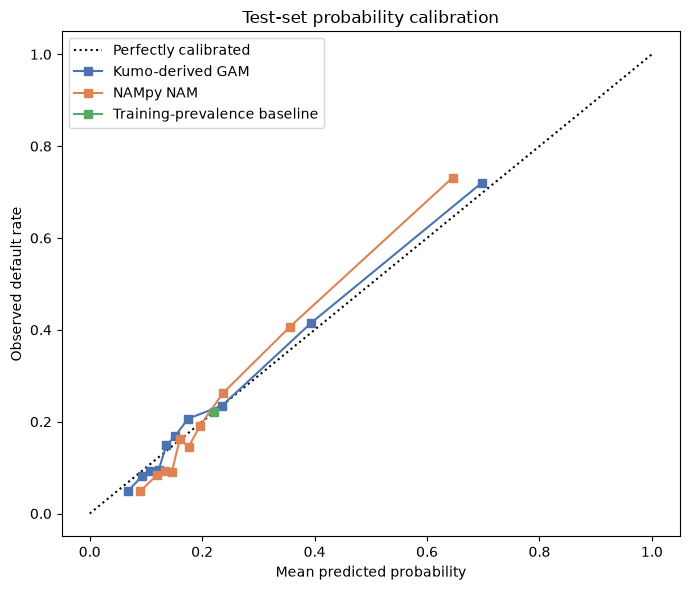

In [17]:
fig, ax = plt.subplots(figsize=(7, 6))
for labels, probabilities, name in [
    (test_labels, kumo_test_probability, "Kumo-derived GAM"),
    (test_labels, nam_test_probability, "NAMpy NAM"),
    (test_labels, constant_probability, "Training-prevalence baseline"),
]:
    CalibrationDisplay.from_predictions(
        labels,
        probabilities,
        n_bins=10,
        strategy="quantile",
        name=name,
        ax=ax,
    )
ax.set_title("Test-set probability calibration")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed default rate")
ax.legend(loc="best")
plt.tight_layout()
plt.show()


## 7. Inspect Additive Main Effects

Each component is evaluated directly from its model. Kumo curves use the cached-context model and are transformed by the fitted logistic coefficient and fold-fitted scaling. NAM curves come from the corresponding feature network in NAMpy's prediction dictionary. Both are centered on the same 512 training reference rows, with the removed means transferred into the intercept. The vertical axis is contribution to log-odds, not probability. Histograms show training support; category codes remain on the original x-axis.

#### Define direct shape-function evaluations

In [18]:
shape_features = x_names

def feature_support_values(feature_name):
    '''Use observed training codes or a supported continuous grid.'''
    if feature_name in categorical_features:
        return np.sort(train_data[feature_name].unique())
    low, high = train_data[feature_name].quantile([0.01, 0.99])
    return np.linspace(low, high, 100)

def make_component_query(feature_name, values):
    '''Copy a training row to supply unused inputs, then vary one feature only.'''
    row = nam_train_data.iloc[[0]][x_names].copy()
    query = pd.concat([row] * len(values), ignore_index=True)
    if feature_name in categorical_features:
        query[feature_name] = [str(value) for value in values]
    else:
        query[feature_name] = values
    query[y_name] = 0  # Placeholder label; prediction uses only formula input columns.
    return query

def evaluate_kumo_component(feature_name, query_frame):
    '''Fit the fixed labeled context and directly score one-feature queries.'''
    context_table = make_kumo_table(context_data, feature_name, include_target=True)
    feature_number = x_names.index(feature_name)
    kumo_model.fit(
        x=context_table.drop_columns(y_name),
        y=context_table[y_name],
        num_estimators=KUMO_NUM_ESTIMATORS,
        generator=torch.Generator(device=KUMO_DEVICE).manual_seed(SEED + feature_number),
    )
    kumo_query_frame = pd.DataFrame({feature_name: query_frame[feature_name].to_numpy()})
    raw_probability = score_kumo_queries(feature_name, kumo_query_frame)
    clipped_probability = np.clip(
        raw_probability,
        KUMO_PROBABILITY_CLIP,
        1.0 - KUMO_PROBABILITY_CLIP,
    )
    raw_feature_logit = logit(clipped_probability)
    return (raw_feature_logit - kumo_reference_means[feature_number]) * (
        combiner_weights[feature_number] / scaler.scale_[feature_number]
    )

def evaluate_nam_component(feature_name, query_frame):
    '''Read this feature network's direct output from the NAM model prediction.'''
    outputs = nam_predict_outputs(nam_model, query_frame)
    feature_number = x_names.index(feature_name)
    return np.asarray(outputs[nam_component_names[feature_number]]).reshape(-1) - nam_reference_means[feature_number]

shape_results = {}
for feature_name in shape_features:
    values = feature_support_values(feature_name)
    query_frame = make_component_query(feature_name, values)
    shape_results[feature_name] = {
        "values": values,
        "kumo": evaluate_kumo_component(
            feature_name,
            pd.DataFrame({feature_name: values}),
        ),
        "nam": evaluate_nam_component(feature_name, query_frame),
    }


#### Plot every centered effect separately with training support

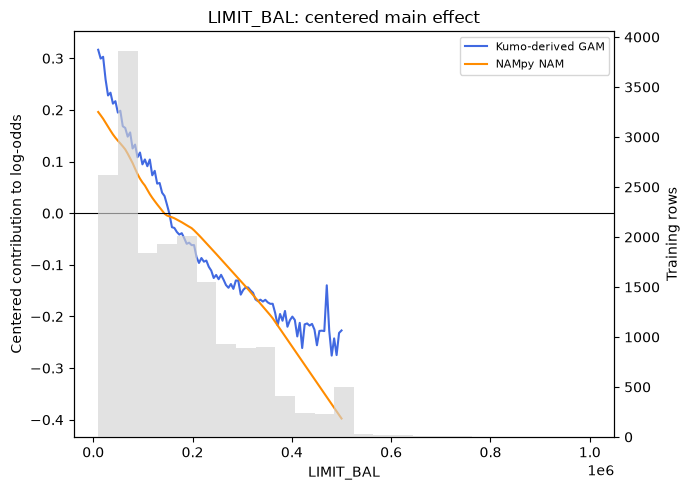

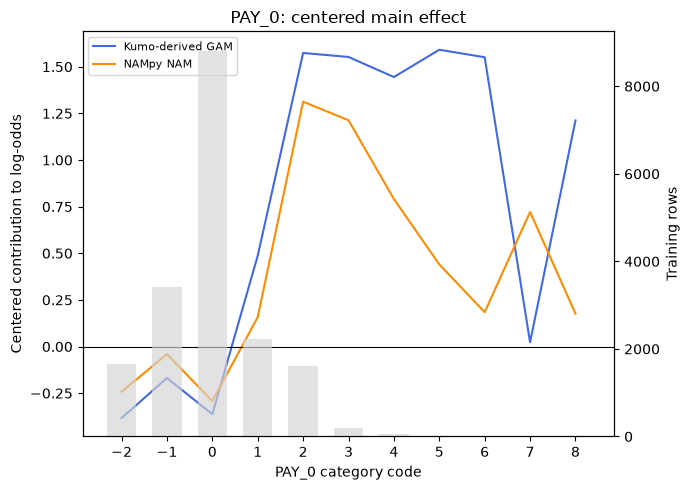

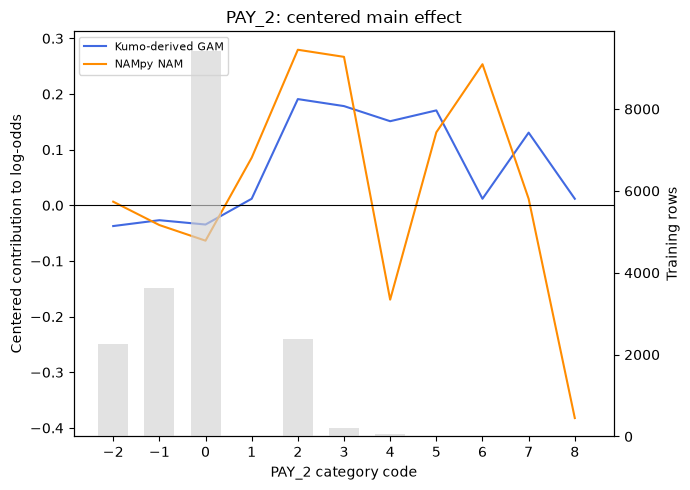

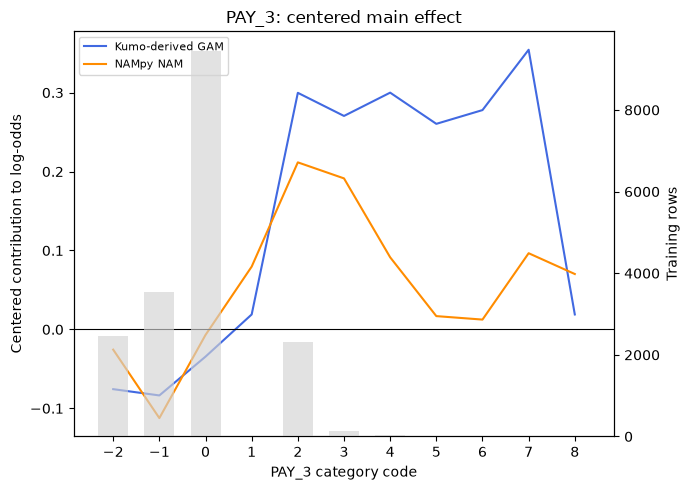

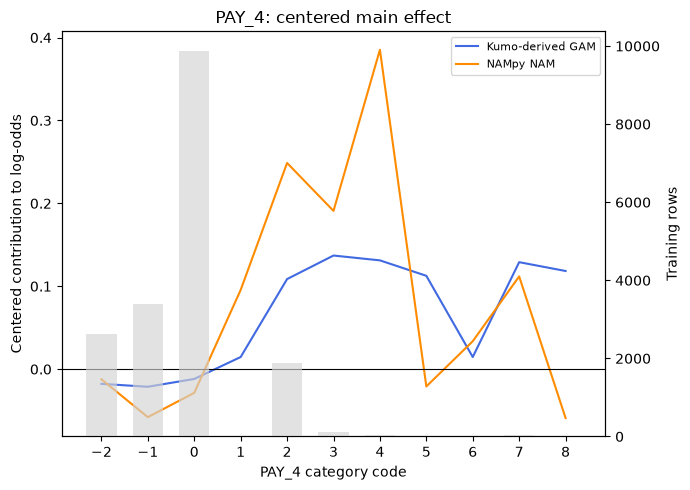

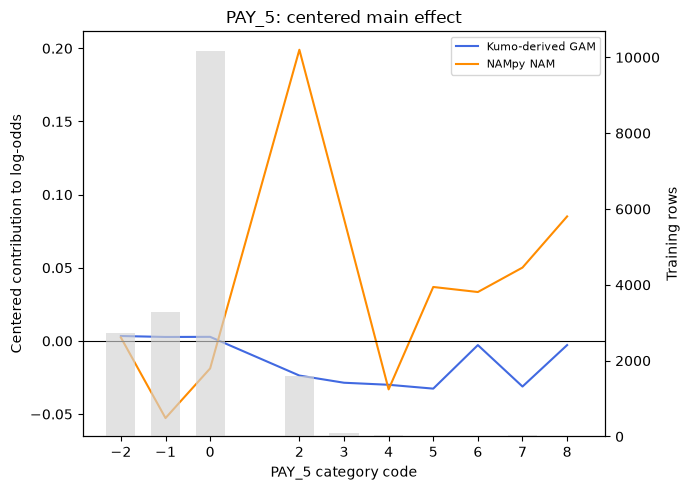

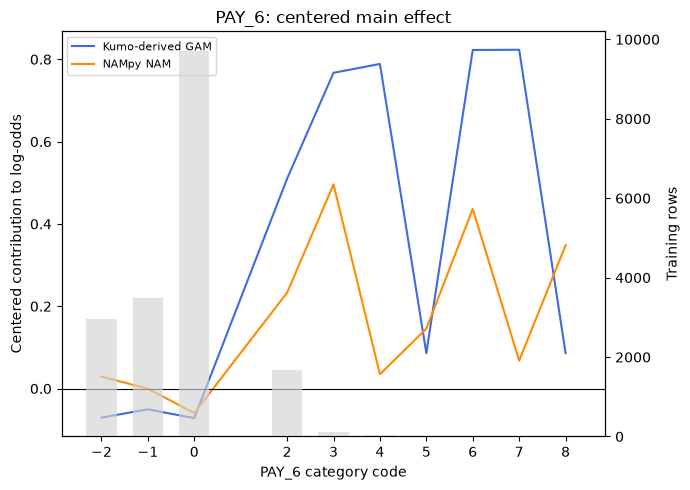

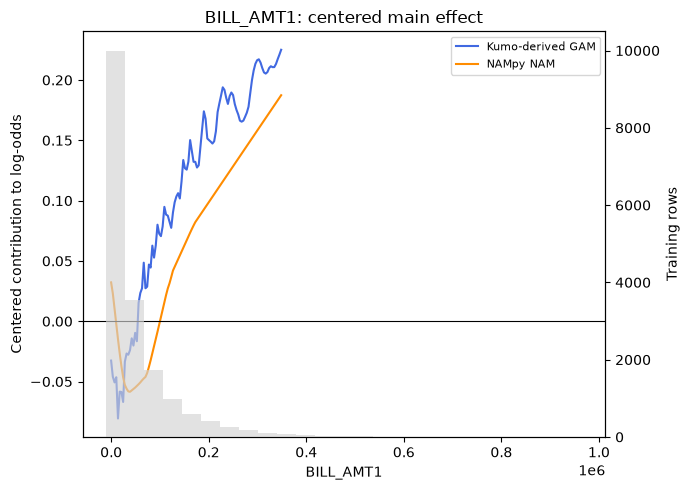

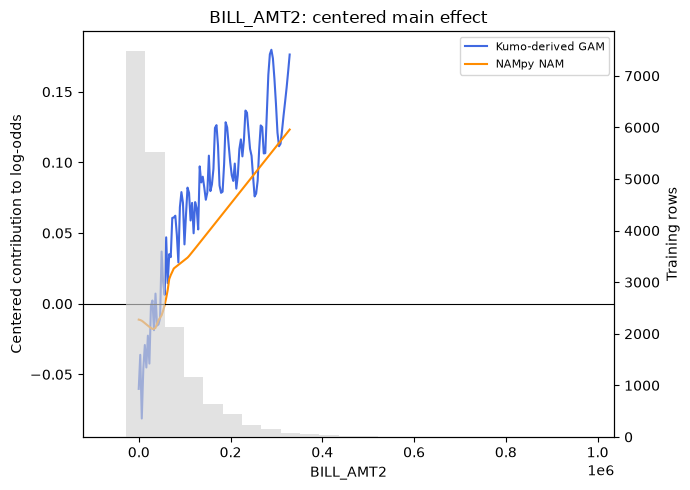

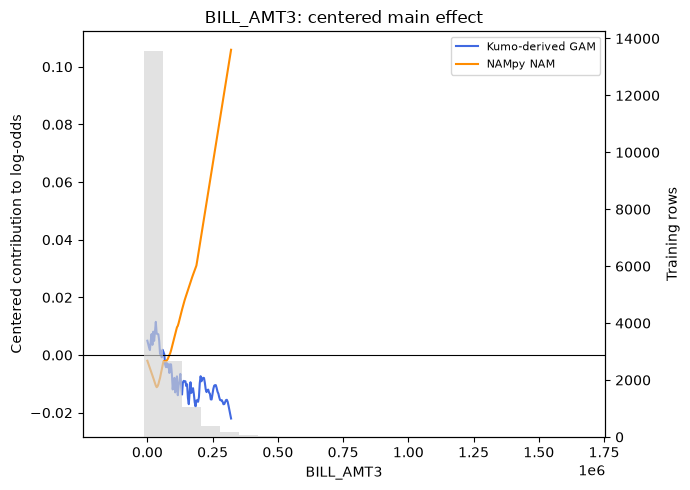

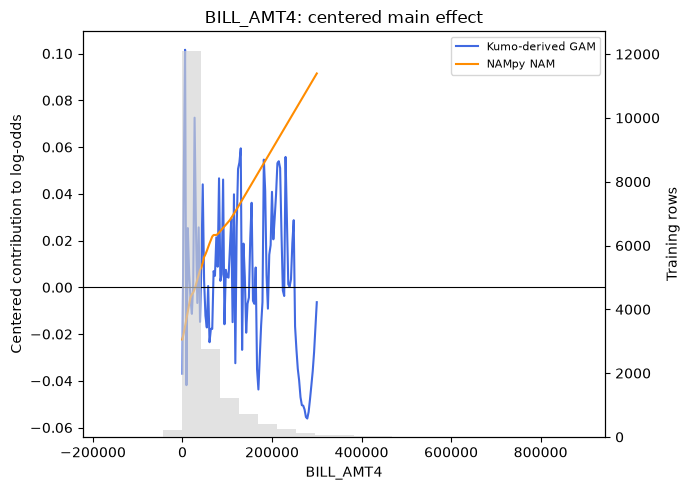

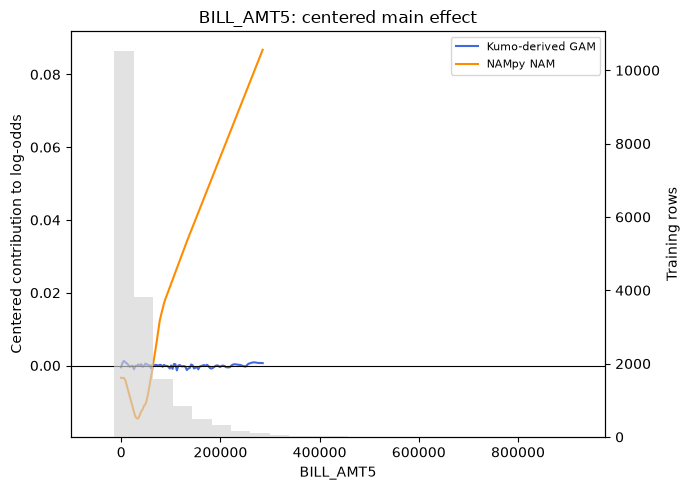

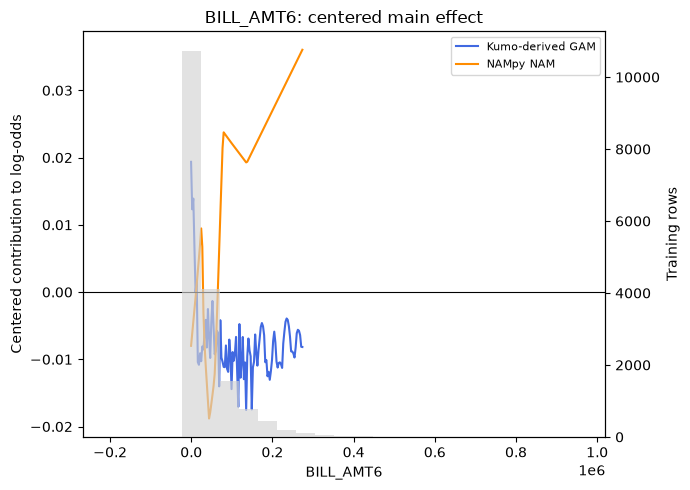

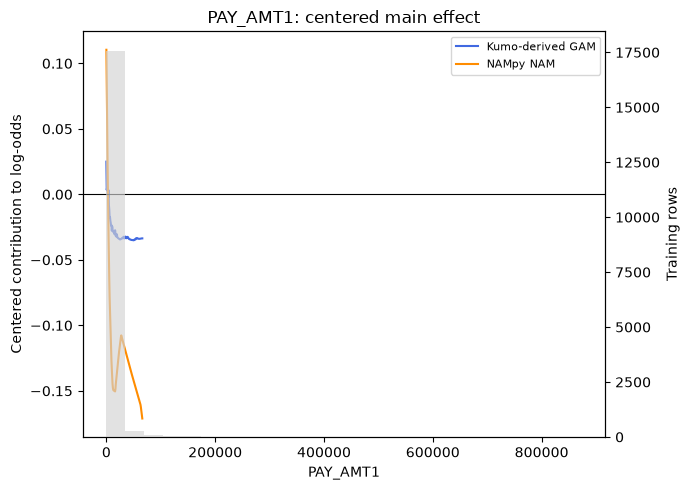

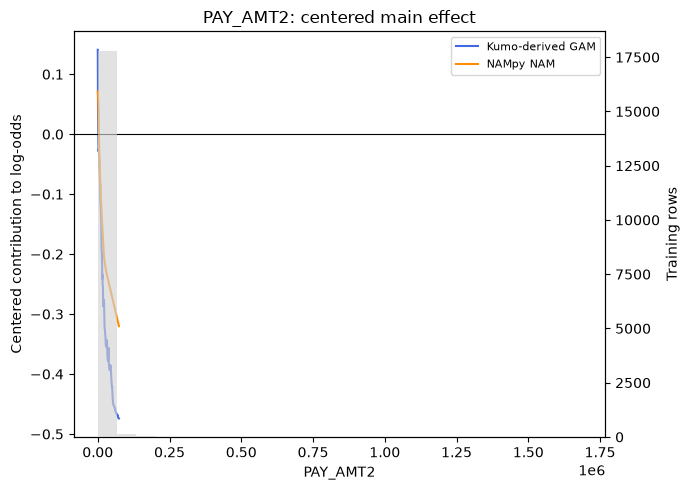

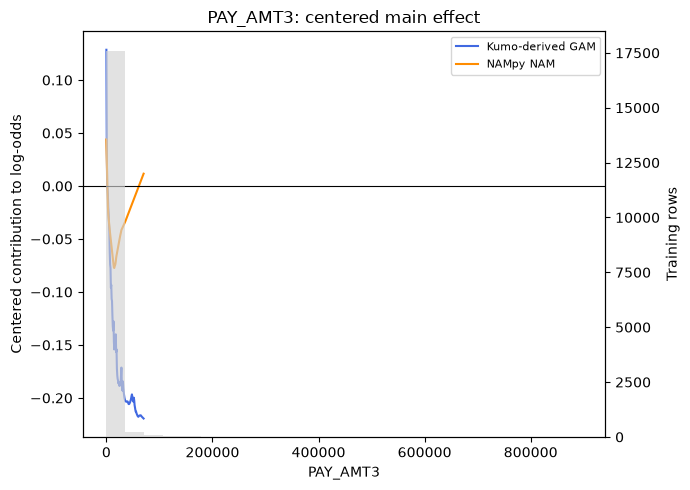

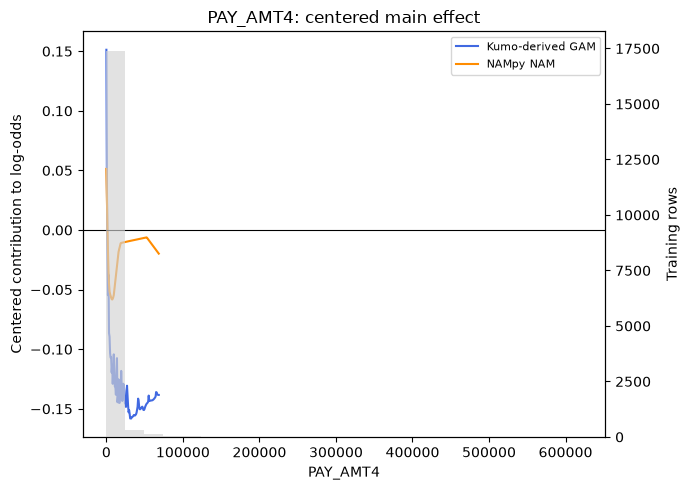

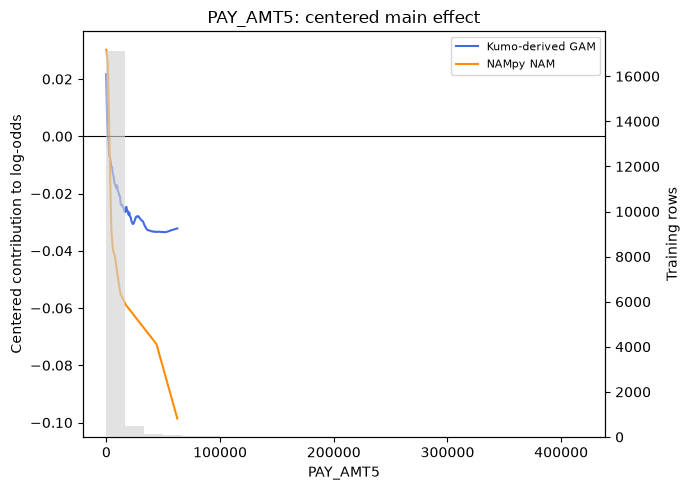

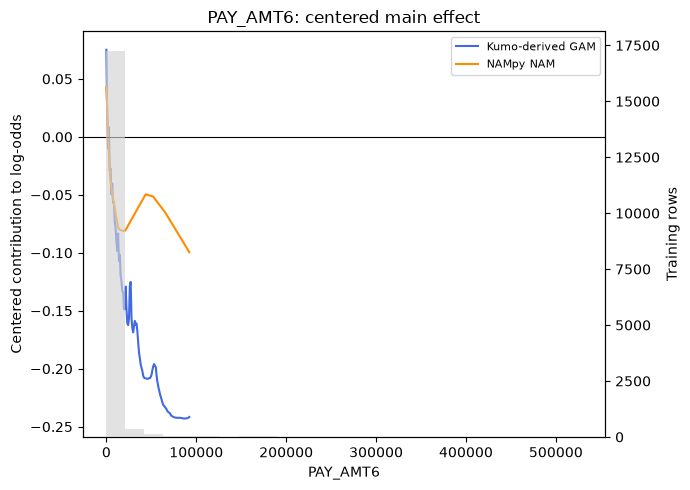

In [19]:
for feature_name in shape_features:
    fig, ax = plt.subplots(figsize=(7, 5))
    values = shape_results[feature_name]["values"]
    ax_hist = ax.twinx()

    if feature_name in categorical_features:
        counts = train_data[feature_name].value_counts().sort_index()
        ax_hist.bar(
            counts.index.to_numpy(),
            counts.values,
            color="lightgray",
            alpha=0.65,
            width=0.65,
            label="Training rows",
        )
        ax.set_xticks(values)
        ax.set_xlabel(f"{feature_name} category code")
    else:
        ax_hist.hist(
            train_data[feature_name],
            bins=25,
            color="lightgray",
            alpha=0.65,
            label="Training rows",
        )
        ax.set_xlabel(feature_name)

    ax.plot(values, shape_results[feature_name]["kumo"], color="royalblue", label="Kumo-derived GAM")
    ax.plot(values, shape_results[feature_name]["nam"], color="darkorange", label="NAMpy NAM")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("Centered contribution to log-odds")
    ax_hist.set_ylabel("Training rows")
    ax.set_title(f"{feature_name}: centered main effect")
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## 8. Inspect Local Feature Contributions

We select three test observations near the 10th, 50th, and 90th percentiles of NAM's predicted default probability. The same observations are shown for both models. For each row, the centered contributions sum with the model's effective intercept to reconstruct the total log-odds. The sigmoid maps that total to the displayed probability. Contributions add on the log-odds scale; they do not add on the probability scale.

#### Choose deterministic test cases

In [20]:
case_positions = {}
for percentile in [10, 50, 90]:
    target_probability = np.percentile(nam_test_probability, percentile)
    case_positions[percentile] = int(np.argmin(np.abs(nam_test_probability - target_probability)))

case_summary = []
for percentile, position in case_positions.items():
    case_summary.append(
        {
            "NAM probability percentile": percentile,
            "test row": position,
            "ID (display only)": int(test_data.iloc[position]["ID"]),
            "NAM default probability": nam_test_probability[position],
            "observed outcome": int(test_labels[position]),
        }
    )
display(pd.DataFrame(case_summary).set_index("NAM probability percentile").round(4))


,test row,ID (display only),NAM default probability,observed outcome
NAM probability percentile,,,,
10,1390,20966,0.1098,0
50,623,20972,0.1677,0
90,5772,20246,0.4817,0


#### Plot signed contributions for the selected observations

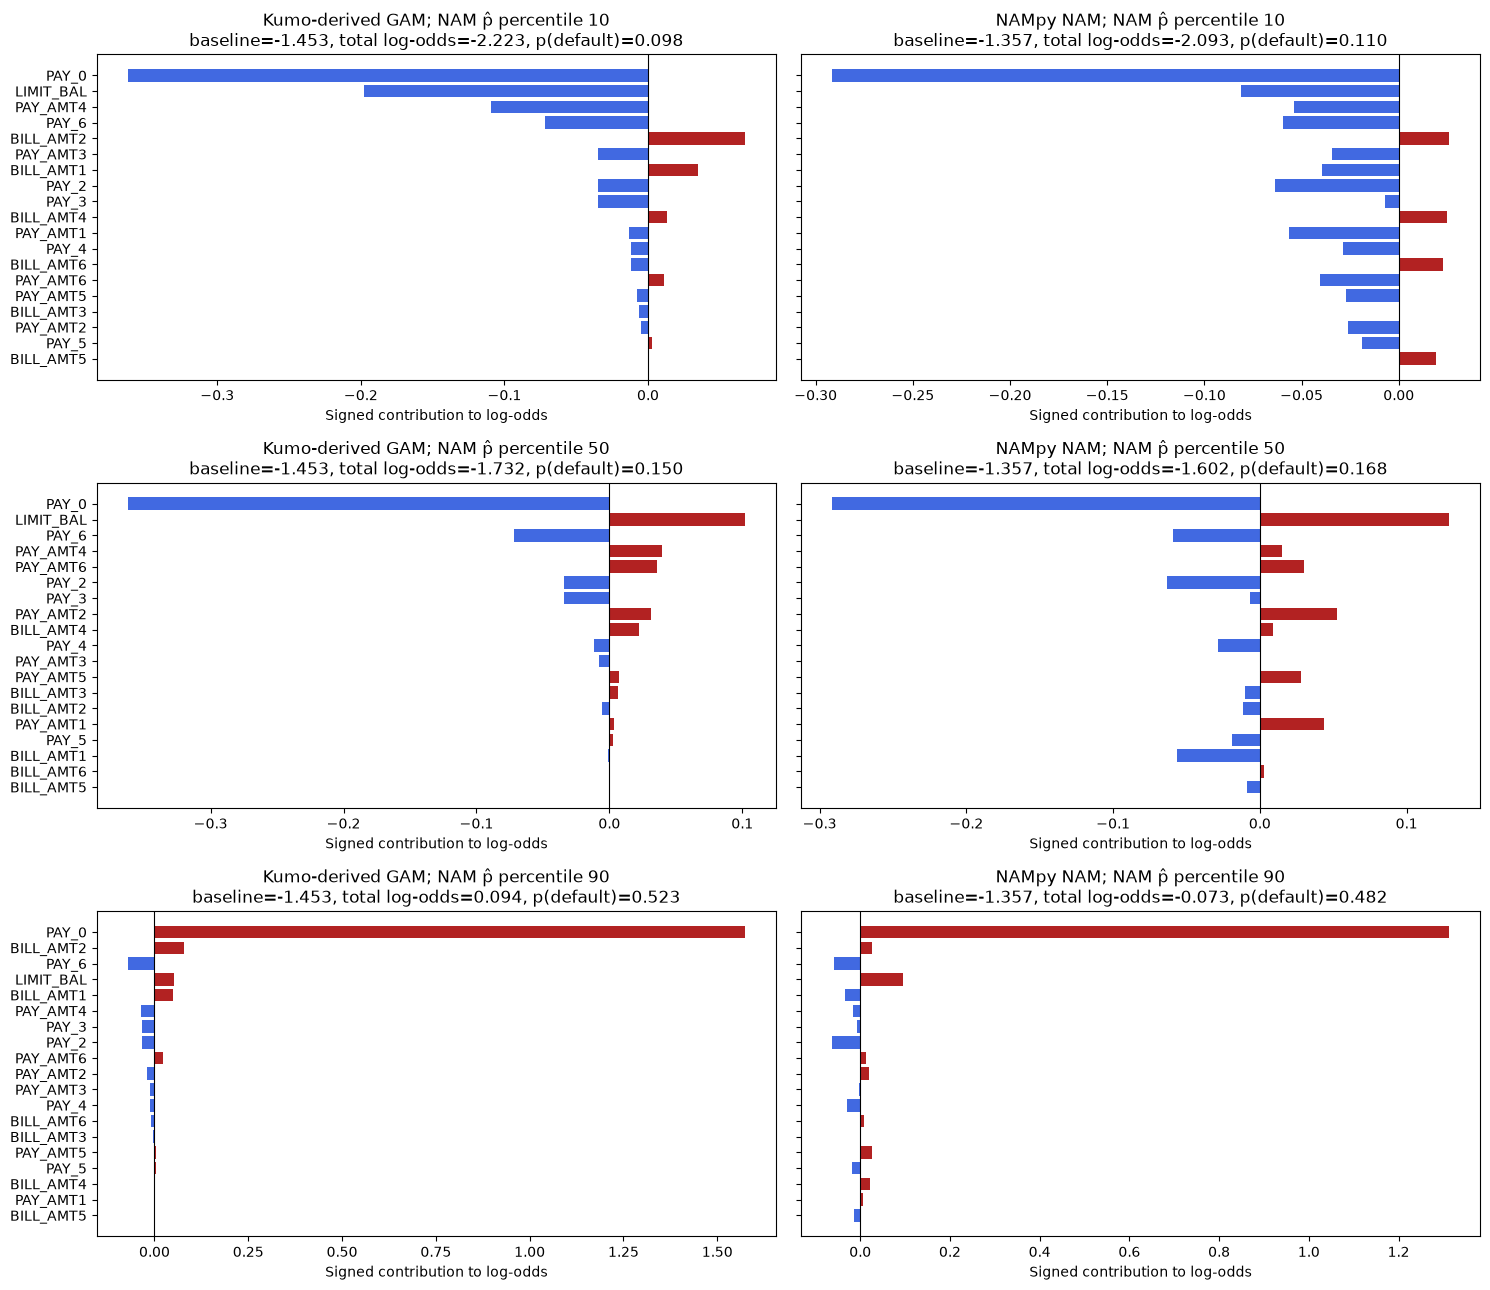

In [21]:
fig, axes = plt.subplots(3, 2, figsize=(15, 13), sharey="row")
model_details = [
    ("Kumo-derived GAM", kumo_centered_intercept, kumo_test_logits, kumo_test_probability, kumo_test_contributions),
    ("NAMpy NAM", nam_centered_intercept, nam_test_logits, nam_test_probability, nam_test_contributions),
]

for row_number, (percentile, position) in enumerate(case_positions.items()):
    for column_number, (model_name, baseline, total_logits, probabilities, contributions) in enumerate(model_details):
        ax = axes[row_number, column_number]
        row_contributions = contributions[position]
        sorted_positions = np.argsort(np.abs(row_contributions))
        ax.barh(
            np.asarray(x_names)[sorted_positions],
            row_contributions[sorted_positions],
            color=np.where(row_contributions[sorted_positions] >= 0, "firebrick", "royalblue"),
        )
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_title(
            f"{model_name}; NAM p̂ percentile {percentile}\n"
            f"baseline={baseline:.3f}, total log-odds={total_logits[position]:.3f}, "
            f"p(default)={probabilities[position]:.3f}"
        )
        ax.set_xlabel("Signed contribution to log-odds")

fig.tight_layout()
plt.show()


#### Verify local contribution reconstruction

In [22]:
local_check_rows = []
for percentile, position in case_positions.items():
    kumo_reconstructed_logit = kumo_centered_intercept + kumo_test_contributions[position].sum()
    nam_reconstructed_logit = nam_centered_intercept + nam_test_contributions[position].sum()
    local_check_rows.extend(
        [
            {
                "NAM probability percentile": percentile,
                "model": "Kumo-derived GAM",
                "direct log-odds": kumo_test_logits[position],
                "reconstructed log-odds": kumo_reconstructed_logit,
                "sigmoid probability": expit(kumo_reconstructed_logit),
            },
            {
                "NAM probability percentile": percentile,
                "model": "NAMpy NAM",
                "direct log-odds": nam_test_logits[position],
                "reconstructed log-odds": nam_reconstructed_logit,
                "sigmoid probability": expit(nam_reconstructed_logit),
            },
        ]
    )

local_check = pd.DataFrame(local_check_rows)
display(local_check.round(6))
assert np.allclose(local_check["direct log-odds"], local_check["reconstructed log-odds"], atol=1e-5)
assert np.allclose(
    local_check["sigmoid probability"],
    [kumo_test_probability[case_positions[p]] if name == "Kumo-derived GAM" else nam_test_probability[case_positions[p]]
     for p, name in zip(local_check["NAM probability percentile"], local_check["model"])],
    atol=1e-6,
)
print("Selected local contributions reconstruct model logits and probabilities.")


,NAM probability percentile,model,direct log-odds,reconstructed log-odds,sigmoid probability
0,10,Kumo-derived GAM,-2.223224,-2.223224,0.097684
1,10,NAMpy NAM,-2.093297,-2.093297,0.109750
2,50,Kumo-derived GAM,-1.731741,-1.731741,0.150365
3,50,NAMpy NAM,-1.602341,-1.602341,0.167655
4,90,Kumo-derived GAM,0.093883,0.093883,0.523453
5,90,NAMpy NAM,-0.073315,-0.073315,0.481679


Selected local contributions reconstruct model logits and probabilities.


## 9. Summary

These two additive models provide a compact way to inspect nonlinear feature associations while retaining a single additive predictor. Kumo's learned feature scores are frozen, pretrained functions combined by a task-specific logistic model; NAMpy learns its feature networks jointly from the training partition. Their validation and test procedures share row partitions but differ in training data access, optimization, and pretraining. The test metrics describe this one split and are not evidence that either model is generally superior.

The curves are model associations on the log-odds scale. Correlated predictors can share or shift apparent effects, category codes summarize the categories supplied in the data, and none of these components establish causal effects. The Kumo-derived GAM is additive because each Kumo component sees only one original feature; claims about interpretability should be limited to that explicit input restriction and additive combiner.

#### Report selected settings and runtime

In [23]:
total_runtime = time.time() - big_tic
print("Kumo: small model, device =", KUMO_DEVICE, ", estimators =", KUMO_NUM_ESTIMATORS, ", context rows =", CONTEXT_SIZE)
print("Kumo probability clipping:", KUMO_PROBABILITY_CLIP)
print("Kumo logistic C:", combiner_search.best_params_["logistic__C"])
print("NAMpy: hidden dimensions [32, 16], feature dropout = 0.05")
print("NAM learning rate:", nam_learning_rate, "; best validation epoch:", best_nam_trial["best_epoch"])
print("NAM early-stopping patience:", NAM_EARLY_STOPPING_PATIENCE)
print("NAMpy TensorFlow devices:", tf.config.list_physical_devices())
print("Full notebook elapsed time: %.1f seconds (%.1f minutes)" % (total_runtime, total_runtime / 60))


Kumo: small model, device = mps , estimators = 8 , context rows = 2048
Kumo probability clipping: 1e-06
Kumo logistic C: 0.01
NAMpy: hidden dimensions [32, 16], feature dropout = 0.05
NAM learning rate: 0.003 ; best validation epoch: 17
NAM early-stopping patience: 6
NAMpy TensorFlow devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
Full notebook elapsed time: 95.3 seconds (1.6 minutes)
